<div align="center">

# Лабораторна робота № 3

### Побудова та оцінювання моделі лінійної регресії

</div>

**Мета:** Набути практичних навичок розв'язання задачі регресії; навчитися відокремлювати ознаки від цільової змінної, запобігати витоку даних, розділяти вибірку на навчальну і тестову частини, порівнювати модель із базовим прогнозом та інтерпретувати MAE, RMSE і коефіцієнт детермінації $R^2$.

<br>

<div align="center">

**Студентка:** Сабадаш Анастасія  
**Група:** МІТ-31

</div>

### Імпорт бібліотек

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

### Створення демонстраційного набору даних

In [66]:
rng = np.random.default_rng(37)
n = 250

area = rng.normal(65, 18, n).clip(25, 140)
rooms = rng.integers(1, 5, n)
floor = rng.integers(1, 21, n)
building_age = rng.integers(0, 60, n)
district = rng.choice(
    ["Центр", "Спальний район", "Передмістя"],
    size=n,
    p=[0.25, 0.50, 0.25],
)

district_effect = {
    "Центр": 9000,
    "Спальний район": 3000,
    "Передмістя": 0,
}

rent = (
    3500
    + area * 220
    + rooms * 1300
    + floor * 90
    - building_age * 55
    + np.array([district_effect[value] for value in district])
    + rng.normal(0, 2500, n)
)

df = pd.DataFrame({
    "area": area.round(1),
    "rooms": rooms,
    "floor": floor,
    "building_age": building_age,
    "district": district,
    "rent": rent.round(2),
})

# Додаємо кілька пропущених значень
missing_area = rng.choice(df.index, size=10, replace=False)
missing_district = rng.choice(df.index, size=8, replace=False)

df.loc[missing_area, "area"] = np.nan
df.loc[missing_district, "district"] = np.nan

df.head()

,area,rooms,floor,building_age,district,rent
0,81.2,1,19,51,Передмістя,18862.79
1,56.7,1,11,18,Спальний район,22588.29
2,41.3,2,19,48,Центр,26337.21
3,76.9,2,14,32,Центр,26708.64
4,82.2,2,20,6,Спальний район,28759.53


### Первинний аналіз даних

In [67]:
print(df.info())
print("\nКількість пропусків:")
print(df.isna().sum())

print("\nКількість дублікатів:")
print(df.duplicated().sum())

print("\nОпис числових показників:")
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area          240 non-null    float64
 1   rooms         250 non-null    int64  
 2   floor         250 non-null    int64  
 3   building_age  250 non-null    int64  
 4   district      242 non-null    str    
 5   rent          250 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 17.1 KB
None

Кількість пропусків:
area            10
rooms            0
floor            0
building_age     0
district         8
rent             0
dtype: int64

Кількість дублікатів:
0

Опис числових показників:
             area       rooms       floor  building_age          rent
count  240.000000  250.000000  250.000000     250.00000    250.000000
mean    64.746250    2.512000   10.632000      28.85600  24039.722720
std     17.511841    1.080057    5.869444      17.65156   5636.333663
min     25.000000 

In [68]:
df = df.drop_duplicates().copy()

### Формування ознак і цільової змінної

In [69]:
X = df.drop(columns="rent")
y = df["rent"]

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

Розмір X: (250, 5)
Розмір y: (250,)


### Розділення даних на навчальну і тестову вибірки

In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=37,
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (200, 5)
Тестова вибірка: (50, 5)


### Визначення груп ознак

In [71]:
numeric_features = [
    "area",
    "rooms",
    "floor",
    "building_age",
]

categorical_features = [
    "district",
]

In [72]:
numeric_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="median"),
    ),
    (
        "scaler",
        StandardScaler(),
    ),
])

categorical_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent"),
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
        ),
    ),
])

### Створення `ColumnTransformer`

In [73]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features,
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features,
        ),
    ]
)

### Побудова базової моделі

In [74]:
dummy_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "model",
        DummyRegressor(strategy="mean"),
    ),
])

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

### Побудова моделі лінійної регресії

In [75]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression()),
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

### Функція для обчислення метрик

In [76]:
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2 = r2_score(y_true, y_pred)
    
    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
    }

In [77]:
dummy_metrics = calculate_metrics(
    y_test,
    dummy_predictions,
)

linear_metrics = calculate_metrics(
    y_test,
    linear_predictions,
)

results = pd.DataFrame(
    [dummy_metrics, linear_metrics],
    index=["DummyRegressor", "LinearRegression"],
)

print(results.round(3))

                       MAE      RMSE     R2
DummyRegressor    3603.308  4796.345 -0.051
LinearRegression  2208.286  2820.607  0.637


### Порівняння фактичних і прогнозованих значень

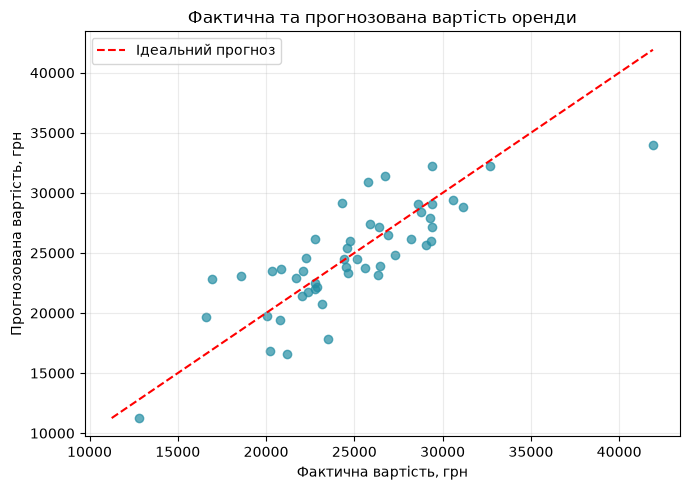

In [78]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    y_test,
    linear_predictions,
    alpha=0.7,
    color="#238DA3",
)

minimum = min(y_test.min(), linear_predictions.min())
maximum = max(y_test.max(), linear_predictions.max())

ax.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red",
    label="Ідеальний прогноз",
)

ax.set(
    title="Фактична та прогнозована вартість оренди",
    xlabel="Фактична вартість, грн",
    ylabel="Прогнозована вартість, грн",
)

ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

plt.show()

### Обчислення та розподіл залишків

In [79]:
residuals = y_test - linear_predictions

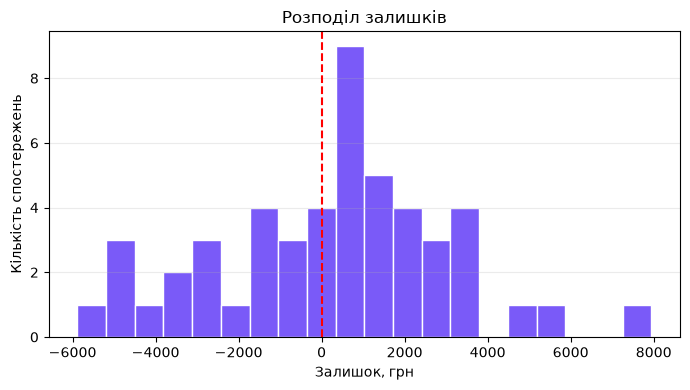

In [80]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    residuals,
    bins=20,
    color="#7A5AF8",
    edgecolor="white",
)

ax.axvline(
    0,
    color="red",
    linestyle="--",
)

ax.set(
    title="Розподіл залишків",
    xlabel="Залишок, грн",
    ylabel="Кількість спостережень",
)

ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

plt.show()

### Залишки залежно від прогнозу

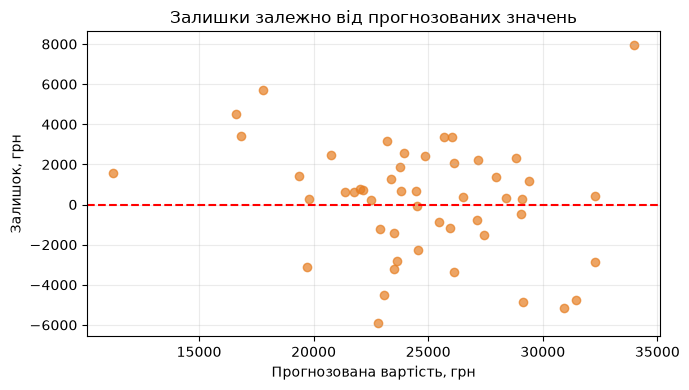

In [81]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    linear_predictions,
    residuals,
    alpha=0.7,
    color="#E67E22",
)

ax.axhline(
    0,
    color="red",
    linestyle="--",
)

ax.set(
    title="Залишки залежно від прогнозованих значень",
    xlabel="Прогнозована вартість, грн",
    ylabel="Залишок, грн",
)

ax.grid(alpha=0.25)
fig.tight_layout()

plt.show()

### Формування таблиці результатів

In [82]:
prediction_results = X_test.copy()

prediction_results["actual_rent"] = y_test
prediction_results["predicted_rent"] = linear_predictions
prediction_results["residual"] = residuals

prediction_results.head()

,area,rooms,floor,building_age,district,actual_rent,predicted_rent,residual
112,84.9,4,10,41,Спальний район,31151.95,28839.079976,2312.870024
30,67.7,4,2,14,Центр,32692.38,32272.372729,420.007271
118,73.8,2,8,51,Спальний район,22105.58,23524.806679,-1419.226679
40,62.5,3,6,25,Спальний район,20863.80,23660.059282,-2796.259282
4,82.2,2,20,6,Спальний район,28759.53,28410.975216,348.554784


In [83]:
prediction_results.to_csv(
    "regression_predictions.csv",
    index=False,
)

results.to_csv(
    "model_metrics.csv",
)

# *Висновок*

У ході лабораторної роботи було побудовано пайплайн машинного навчання для прогнозування вартості оренди житла, що включає попередню обробку даних (ColumnTransformer), заповнення пропусків, масштабування та One-Hot кодування. Порівняння за метриками MAE, RMSE та R² підтвердило значну перевагу лінійної регресії над базовою моделлю (DummyRegressor), а візуальний аналіз залишків продемонстрував адекватність та високу точність отриманих прогнозів, які разом із метриками було успішно експортовано в CSV-файли.